In [252]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,6456,33,admin.,married,secondary,no,2,yes,no,unknown,20,may,201,1,-1,0,unknown,0
1,5432,35,technician,married,secondary,no,545,yes,no,cellular,16,apr,1579,1,234,4,failure,1
2,6372,39,management,married,tertiary,no,763,yes,no,cellular,11,may,877,7,300,2,other,1
3,2254,37,management,married,tertiary,no,5106,no,no,cellular,30,apr,244,1,-1,0,unknown,1
4,8350,30,unemployed,married,tertiary,no,330,no,no,cellular,14,apr,111,1,-1,0,unknown,1


In [253]:
#subtasks
df_depo = df_train[df_train.deposit == 1].groupby("job").size()
df_full = df_train.groupby("job").size()
jobs = df_train.job.unique()

rates = {}
for job in jobs:
    rates[job] = df_depo[job] / df_full[job]

subtask1 = max(rates, key=rates.get)
subtask2 = df_train.month.value_counts().idxmax()

df_1 = pd.DataFrame({
    "subtaskID": [1, 2],
    "datapointID": [1, 1],
    "answer": [subtask1, subtask2]
})

df_1

,subtaskID,datapointID,answer
0,1,1,student
1,2,1,may


In [254]:
from sklearn.preprocessing import LabelEncoder
to_enc = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
X_enc = pd.get_dummies(df_train[to_enc])
X_enc_final = pd.get_dummies(df_test[to_enc])

df_train = df_train.drop(columns=to_enc)
df_test = df_test.drop(columns=to_enc)

df_train = pd.concat([df_train, X_enc], axis=1)
df_test = pd.concat([df_test, X_enc_final], axis=1)

df_train.head()

,id,age,balance,day,duration,campaign,pdays,previous,deposit,job_admin.,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,6456,33,2,20,201,1,-1,0,0,True,...,False,False,True,False,False,False,False,False,False,True
1,5432,35,545,16,1579,1,234,4,1,False,...,False,False,False,False,False,False,True,False,False,False
2,6372,39,763,11,877,7,300,2,1,False,...,False,False,True,False,False,False,False,True,False,False
3,2254,37,5106,30,244,1,-1,0,1,False,...,False,False,False,False,False,False,False,False,False,True
4,8350,30,330,14,111,1,-1,0,1,False,...,False,False,False,False,False,False,False,False,False,True


In [255]:
features = [col for col in df_test.columns if col != 'id']
target = 'deposit'

X = df_train[features]
y = df_train[target]
X_final = df_test[features]

X.head()

,age,balance,day,duration,campaign,pdays,previous,job_admin.,job_blue-collar,job_entrepreneur,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,33,2,20,201,1,-1,0,True,False,False,...,False,False,True,False,False,False,False,False,False,True
1,35,545,16,1579,1,234,4,False,False,False,...,False,False,False,False,False,False,True,False,False,False
2,39,763,11,877,7,300,2,False,False,False,...,False,False,True,False,False,False,False,True,False,False
3,37,5106,30,244,1,-1,0,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,30,330,14,111,1,-1,0,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [256]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score

model = LGBMClassifier()

cross_val_score(model, X, y, cv=5, scoring='f1_macro').mean()

0.8613777888053209

In [257]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [258]:
df_2 = pd.DataFrame({
    "subtaskID": 3,
    "datapointID": df_test.id,
    "answer": y_preds
})

df_2.head()

,subtaskID,datapointID,answer
0,3,5686,0
1,3,5206,1
2,3,5160,0
3,3,5016,1
4,3,1297,1


In [259]:
num_feat = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
X_final = X_final[num_feat]

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_final = pd.DataFrame(scaler.fit_transform(X_final), columns=num_feat)

X_final.head()

,age,balance,day,duration,campaign,pdays,previous
0,1.336611,-0.330872,-0.530048,-0.669644,1.022197,-0.481649,-0.331174
1,0.285962,0.064550,-1.713765,-0.587040,-0.194523,-0.481649,-0.331174
2,0.124323,-0.097683,1.482270,-0.171073,-0.194523,-0.481649,-0.331174
3,-0.441411,-0.159931,-1.358650,-0.631292,-0.600096,-0.481649,-0.331174
4,1.498250,0.333540,-1.595393,0.147541,-0.600096,-0.481649,-0.331174


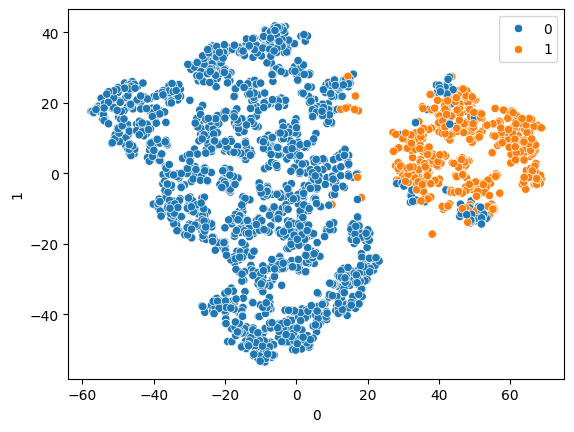

In [264]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

decom = TSNE(n_components=2)
X_red = pd.DataFrame(decom.fit_transform(X_final))

model = KMeans(n_clusters=2)
labels = model.fit_predict(X_final)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=labels)
plt.show()

In [261]:
df_3 = pd.DataFrame({
    "subtaskID": 4,
    "datapointID": df_test.id,
    "answer": labels
})

df_3.head()

,subtaskID,datapointID,answer
0,4,5686,0
1,4,5206,0
2,4,5160,0
3,4,5016,0
4,4,1297,0


In [262]:
submission = pd.concat([df_1, df_2, df_3])
submission

,subtaskID,datapointID,answer
0,1,1,student
1,2,1,may
0,3,5686,0
1,3,5206,1
2,3,5160,0
...,...,...,...
2228,4,11118,1
2229,4,7473,1
2230,4,8804,0
2231,4,4076,0


In [263]:
submission.to_csv("submission.csv", index=False)